# Digital Audio Equalizer
### Design and Implementation of a Three-Band FIR-Based Audio Equalizer

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import firwin, lfilter, freqz, welch

os.makedirs("figures", exist_ok=True)

## Helper Functions

This section defines helper functions used throughout the project:
- conversion from decibels (dB) to linear amplitude,
- normalization of the output signal to prevent clipping,
- computation of the magnitude response (dB) of an FIR filter.

In [2]:
def db_to_linear(db: float) -> float:
    """Convert gain from dB to linear amplitude scale."""
    return 10 ** (db / 20.0)

def normalize_audio(x: np.ndarray, peak: float = 0.99) -> np.ndarray:
    """Normalize an audio signal so its peak absolute value is approximately `peak`."""
    m = np.max(np.abs(x)) + 1e-12
    return (x / m) * peak

def magnitude_response(h: np.ndarray, fs: int, n_points: int = 8192):
    """Return frequency axis (Hz) and magnitude response (dB) of an FIR filter."""
    w, H = freqz(h, worN=n_points)
    f = (w / (2 * np.pi)) * fs
    mag = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
    return f, mag

## Load Audio Signal

The input WAV file is loaded from disk. The sampling rate `fs` and the sample array `x` are extracted.
The audio is converted to floating-point representation, and a stereo signal is converted to mono by averaging the channels.

If `input.wav` is not present, a test signal is generated instead: three tones, one in each band (100 Hz, 1000 Hz and 8000 Hz), plus low-level white noise. With one tone per band, the gain applied to each band can be measured directly.

In [3]:
INPUT_WAV = "input.wav"          # put your own WAV file here
TEST_WAV = "test_signal.wav"     # generated when INPUT_WAV is missing
TEST_TONES_HZ = [100, 1000, 8000]

if os.path.exists(INPUT_WAV):
    source = INPUT_WAV
else:
    fs_gen, dur = 44100, 5.0
    t_gen = np.arange(int(fs_gen * dur)) / fs_gen
    rng = np.random.default_rng(0)
    sig = sum(0.2 * np.sin(2 * np.pi * f0 * t_gen) for f0 in TEST_TONES_HZ)
    sig = sig + 0.01 * rng.standard_normal(len(t_gen))
    wavfile.write(TEST_WAV, fs_gen, np.int16(np.clip(sig, -1, 1) * 32767))
    source = TEST_WAV

fs, x = wavfile.read(source)

# Convert to float [-1, 1] depending on input dtype
if x.dtype == np.int16:
    x = x.astype(np.float32) / 32768.0
elif x.dtype == np.int32:
    x = x.astype(np.float32) / 2147483648.0
else:
    x = x.astype(np.float32)

# If stereo -> mono (simple average)
if x.ndim == 2:
    x = x.mean(axis=1)

print(f"Loaded {source} | fs={fs} Hz | samples={len(x)} | duration={len(x)/fs:.2f} s")

Loaded test_signal.wav | fs=44100 Hz | samples=220500 | duration=5.00 s


## Frequency Band Definition

The equalizer has three frequency bands:
- Bass: frequencies below 250 Hz
- Midrange: frequencies between 250 Hz and 4000 Hz
- Treble: frequencies above 4000 Hz

The bands share their edges, so together they cover the whole spectrum from 0 Hz to `fs/2`.

In [4]:
bass_hi = 250
mid_lo, mid_hi = 250, 4000
treble_lo = 4000

## FIR Filter Parameters

This section sets the FIR filter length (number of taps).
A larger number of taps gives sharper transitions between the bands, but increases the computational cost and the delay.
An odd number of taps gives a symmetric (linear-phase) filter with an integer delay of `(N - 1) / 2` samples.

In [5]:
N = 801
group_delay = (N - 1) // 2
print(f"Filter length: {N} taps | group delay: {group_delay} samples = {1000 * group_delay / fs:.2f} ms")

Filter length: 801 taps | group delay: 400 samples = 9.07 ms


## FIR Filter Design

Three FIR filters are designed with the window method (`firwin`, Hamming window):
- a low-pass filter for the bass band,
- a band-pass filter for the midrange band,
- a high-pass filter for the treble band.

In [6]:
h_bass = firwin(N, bass_hi, fs=fs, pass_zero="lowpass")
h_mid  = firwin(N, [mid_lo, mid_hi], fs=fs, pass_zero="bandpass")
h_treb = firwin(N, treble_lo, fs=fs, pass_zero="highpass")

## Filter Frequency Responses

The magnitude response of each filter is plotted on a logarithmic frequency axis to check that it isolates the intended band.

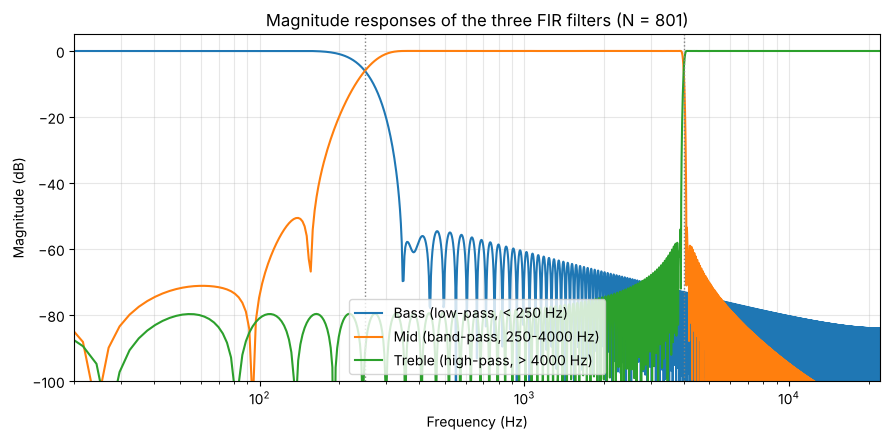

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for h, name in [(h_bass, "Bass (low-pass, < 250 Hz)"),
                (h_mid,  "Mid (band-pass, 250-4000 Hz)"),
                (h_treb, "Treble (high-pass, > 4000 Hz)")]:
    f, mag = magnitude_response(h, fs)
    ax.semilogx(f[1:], mag[1:], label=name)
for edge in (bass_hi, mid_hi):
    ax.axvline(edge, color="gray", linestyle=":", linewidth=1)
ax.set_xlim(20, fs / 2)
ax.set_ylim(-100, 5)
ax.set_title(f"Magnitude responses of the three FIR filters (N = {N})")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower center")
fig.tight_layout()
fig.savefig("figures/filter_responses.png", dpi=150)
plt.show()

### Check: the three bands add up to the original signal

With all gains at 0 dB, the equalizer should leave the signal unchanged apart from the delay.
This holds if the sum of the three impulse responses is close to a pure delay, that is, if its magnitude response is flat at 0 dB.

In [8]:
h_sum = h_bass + h_mid + h_treb
f, mag_sum = magnitude_response(h_sum, fs)
audible = (f >= 20) & (f <= 20000)
flat_dev = np.max(np.abs(mag_sum[audible]))
print(f"Largest deviation from 0 dB between 20 Hz and 20 kHz (all gains at 0 dB): {flat_dev:.3f} dB")

Largest deviation from 0 dB between 20 Hz and 20 kHz (all gains at 0 dB): 0.005 dB


## Signal Filtering

The input signal is filtered three times, once per band. This gives three band-limited signals:
- `y_b` for the bass content
- `y_m` for the midrange content
- `y_t` for the treble content

In [9]:
y_b = lfilter(h_bass, 1.0, x)
y_m = lfilter(h_mid,  1.0, x)
y_t = lfilter(h_treb, 1.0, x)

## Gain Application and Recombination

A gain in decibels (dB) is set for each band and converted to linear scale.
Each band signal is multiplied by its gain, and the three are summed to give the equalized output.

A positive value boosts a band, a negative value attenuates it, and 0 dB leaves it unchanged.

In [10]:
Gb_db = 12   # bass boost
Gm_db = 6    # mid boost
Gt_db = 0    # treble unchanged

gb = db_to_linear(Gb_db)
gm = db_to_linear(Gm_db)
gt = db_to_linear(Gt_db)

y_eq = gb * y_b + gm * y_m + gt * y_t

### Check: measured gain in each band

The gain actually applied is measured by comparing the input and output amplitude at one frequency in each band.
The first `N` output samples are skipped, because they contain the start-up transient of the filters.
For the generated test signal the three frequencies are exactly the three tones.

In [11]:
def tone_amplitude(sig: np.ndarray, f0: float, fs: int) -> float:
    """Amplitude of the component of `sig` at frequency f0 (single-bin DFT)."""
    n = np.arange(len(sig))
    return 2 * np.abs(np.mean(sig * np.exp(-2j * np.pi * f0 * n / fs)))

seg_in, seg_out = x[N:], y_eq[N:]
print("Frequency   Band     Set gain   Measured gain")
for f0, band, g_db in zip(TEST_TONES_HZ, ["bass", "mid", "treble"], [Gb_db, Gm_db, Gt_db]):
    measured = 20 * np.log10(tone_amplitude(seg_out, f0, fs) / tone_amplitude(seg_in, f0, fs))
    print(f"{f0:>6} Hz   {band:<7}  {g_db:>+5.1f} dB   {measured:>+6.2f} dB")

Frequency   Band     Set gain   Measured gain
   100 Hz   bass     +12.0 dB   +12.00 dB
  1000 Hz   mid       +6.0 dB    +6.01 dB
  8000 Hz   treble    +0.0 dB    -0.00 dB


## Output Normalization

After recombination, the signal can exceed the range [-1, 1] and clip.
The output is normalized so that its largest absolute value is 0.99.

In [12]:
y = normalize_audio(y_eq)
print(f"Peak before normalization: {np.max(np.abs(y_eq)):.3f} | after: {np.max(np.abs(y)):.3f}")

Peak before normalization: 1.396 | after: 0.990


## Equalized Audio

The output is converted to 16-bit integer format and saved to a WAV file, so that the effect of the equalizer can be heard.

In [13]:
out_int16 = np.int16(np.clip(y, -1, 1) * 32767)
wavfile.write("equalized_output.wav", fs, out_int16)
print("Output saved: equalized_output.wav")

Output saved: equalized_output.wav


## Spectrum Before and After

The power spectral density of the input and of the equalized signal (before normalization) is estimated with Welch's method.
The difference between the two curves in each band is the gain of that band.

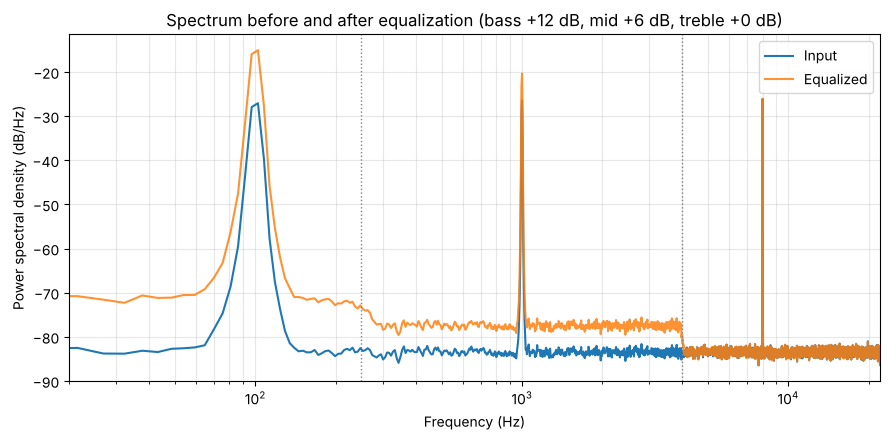

In [14]:
f_in,  P_in  = welch(x[N:],    fs=fs, nperseg=8192)
f_out, P_out = welch(y_eq[N:], fs=fs, nperseg=8192)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogx(f_in[1:],  10 * np.log10(P_in[1:]  + 1e-20), label="Input")
ax.semilogx(f_out[1:], 10 * np.log10(P_out[1:] + 1e-20), label="Equalized", alpha=0.85)
for edge in (bass_hi, mid_hi):
    ax.axvline(edge, color="gray", linestyle=":", linewidth=1)
ax.set_xlim(20, fs / 2)
ax.set_title(f"Spectrum before and after equalization (bass {Gb_db:+d} dB, mid {Gm_db:+d} dB, treble {Gt_db:+d} dB)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power spectral density (dB/Hz)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("figures/spectrum_before_after.png", dpi=150)
plt.show()

## Time-Domain Plot

A short segment of the original and of the equalized (normalized) signal is plotted.
The equalized signal is shifted back by the group delay of the filters, `(N - 1) / 2` samples, so that the two waveforms are aligned.

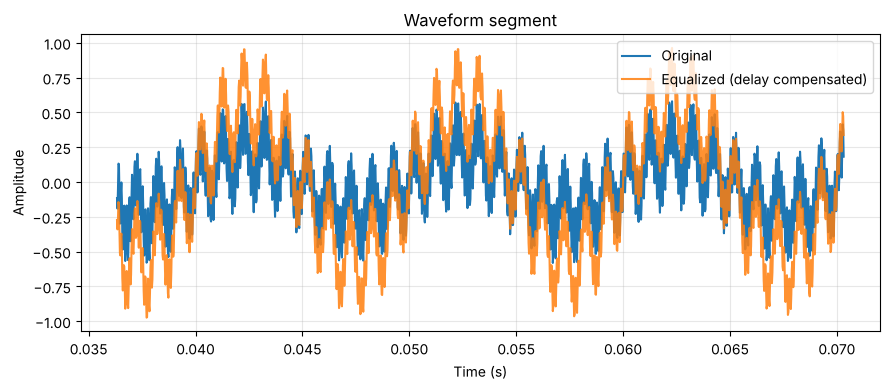

In [15]:
start, length = 2 * N, 1500
idx = np.arange(start, start + length)
t = idx / fs

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, x[idx], label="Original")
ax.plot(t, y[idx + group_delay], label="Equalized (delay compensated)", alpha=0.85)
ax.set_title("Waveform segment")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("figures/waveform.png", dpi=150)
plt.show()